In [1]:
from pathlib import Path
import subprocess
import sys

REPO_URL = "https://github.com/Tralaiday/NLP.git"
REPO_BRANCH = "main"
REPO_DIR = Path("/kaggle/working/NLP")

if not (REPO_DIR / "Lab8").exists():
    subprocess.run(
        ["git", "clone", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "origin", REPO_BRANCH], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "-q", REPO_BRANCH], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "reset", "--hard", f"origin/{REPO_BRANCH}"], check=True)

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

print("Repository:", REPO_DIR)
print("Lab8 exists:", (REPO_DIR / "Lab8").exists())

Cloning into '/kaggle/working/NLP'...


Repository: /kaggle/working/NLP
Lab8 exists: True


Updating files: 100% (79/79), done.


In [2]:
import importlib.util
import subprocess
import sys

packages = {
    "transformers": "transformers",
    "datasets": "datasets",
    "seaborn": "seaborn",
}
for module_name, package_name in packages.items():
    if importlib.util.find_spec(module_name) is None:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", package_name],
            check=True,
        )

import os
import random
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix
from transformers import AutoTokenizer
from Lab8.src.pretrained_classification import (
    IMDbDataset,
    PretrainedClassifier,
    count_parameters,
    evaluate,
    fit,
    load_imdb,
    set_seed,
    split_imdb,
)

OUTPUT_DIR = REPO_DIR / "Lab8"
OUTPUT_DIR.mkdir(exist_ok=True)
DATA_PATH = OUTPUT_DIR / "data" / "IMDB Dataset.csv"
MODEL_NAME = "distilbert-base-uncased"
SEED = 2026
MAX_LENGTH = 128
BATCH_SIZES = {64: 128, 128: 64, 256: 16}
EPOCHS = 5
LEARNING_RATE = 2e-5
NUM_WORKERS = 2
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
set_seed(SEED)
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
print("Device:", device)
print("GPU count:", torch.cuda.device_count())
if torch.cuda.is_available():
    for gpu_index in range(torch.cuda.device_count()):
        print(f"GPU {gpu_index}:", torch.cuda.get_device_name(gpu_index))

Device: cuda:0
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


- Dataset, tokenizer và các hàm dùng chung

In [3]:
MAX_TRAIN_SAMPLES = 10000
data = load_imdb(str(DATA_PATH))
train_df, validation_df, test_df = split_imdb(data, seed=SEED)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if MAX_TRAIN_SAMPLES is not None:
    train_df = train_df.sample(
        n=min(MAX_TRAIN_SAMPLES, len(train_df)),
        random_state=SEED,
    ).reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))
print("Tokenizer:", MODEL_NAME)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Train: 10000
Validation: 10000
Test: 10000
Tokenizer: distilbert-base-uncased


In [4]:
results = []
dataset_cache = {}

def make_loader(frame, max_length, shuffle):
    cache_key = (id(frame), max_length)
    if cache_key not in dataset_cache:
        dataset_cache[cache_key] = IMDbDataset(
            frame,
            tokenizer,
            max_length=max_length,
        )
    return DataLoader(
        dataset_cache[cache_key],
        batch_size=BATCH_SIZES[max_length],
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=False,
    )

def prepare_model(model):
    """Place a model on GPU 0 and replicate it across Kaggle GPUs."""
    model = model.to(device)
    if torch.cuda.device_count() > 1:
        model = nn.DataParallel(
            model,
            device_ids=list(range(torch.cuda.device_count())),
            output_device=0,
        )
    return model

def new_pretrained(freeze_encoder=False):
    return PretrainedClassifier(
        model_name=MODEL_NAME,
        freeze_encoder=freeze_encoder,
    )

class ScratchClassifier(nn.Module):
    """Small randomly initialized Transformer encoder for Experiment 1."""

    def __init__(self, vocab_size, max_length, hidden_size=128, heads=4, layers=2):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, hidden_size)
        self.position_embedding = nn.Embedding(max_length, hidden_size)
        layer = nn.TransformerEncoderLayer(
            d_model=hidden_size,
            nhead=heads,
            dim_feedforward=hidden_size * 2,
            dropout=0.1,
            batch_first=True,
            activation="gelu",
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=layers)
        self.classifier = nn.Linear(hidden_size, 2)
        self.max_length = max_length

    def forward(self, input_ids, attention_mask):
        positions = torch.arange(
            input_ids.size(1), device=input_ids.device
        ).unsqueeze(0)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.encoder(x, src_key_padding_mask=~attention_mask.bool())
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (x * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.classifier(pooled)

def train_and_test(model, train_frame, validation_frame, test_frame, max_length, evaluate_test=True):
    train_loader = make_loader(train_frame, max_length, shuffle=True)
    validation_loader = make_loader(validation_frame, max_length, shuffle=False)
    test_loader = make_loader(test_frame, max_length, shuffle=False)
    model = prepare_model(model)
    training = fit(
        model,
        train_loader,
        validation_loader,
        device,
        epochs=EPOCHS,
        learning_rate=LEARNING_RATE,
    )
    if evaluate_test:
        metrics = evaluate(model, test_loader, device)
    else:
        metrics = training["validation_metrics"]
    return model, training, metrics

def add_result(name, model, metrics, training, max_length, train_size):
    results.append({
        "experiment": name,
        "model": MODEL_NAME,
        "train_size": train_size,
        "max_length": max_length,
        "accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
        "evaluation_split": "validation" if metrics is training["validation_metrics"] else "test",
        "training_time_seconds": training["training_time_seconds"],
        "parameters": count_parameters(model),
        "trainable_parameters": count_parameters(model, trainable_only=True),
    })

def plot_loss(histories, title, filename):
    plt.figure(figsize=(7, 4))
    for label, history in histories.items():
        epochs = [item["epoch"] for item in history]
        train_loss = [item["train_loss"] for item in history]
        validation_loss = [item["validation_loss"] for item in history]
        plt.plot(epochs, train_loss, marker="o", label=f"{label} train")
        plt.plot(epochs, validation_loss, marker="x", linestyle="--", label=f"{label} validation")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    path = OUTPUT_DIR / filename
    plt.savefig(path, dpi=150)
    plt.show()
    return path

# Experiment 1: Pretrained vs From scratch

/kaggle/working/NLP/Lab8/src/pretrained_classification.py:245: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:158: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:196: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type == "cuda"):
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:158: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/working/NLP/Lab

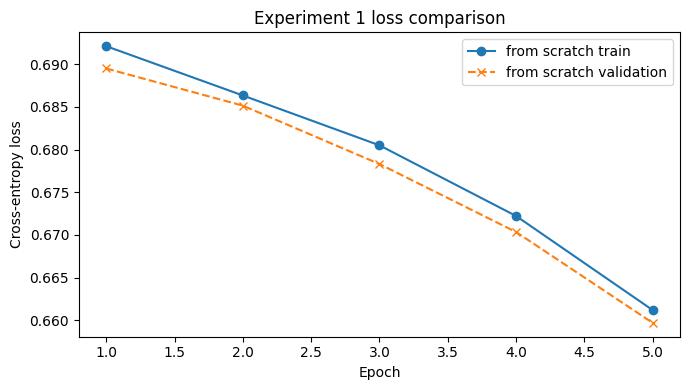

,experiment,accuracy,f1,training_time_seconds,parameters
0,Experiment 1 - from scratch,0.6191,0.642247,31.007458,4188418


In [5]:
scratch_model = ScratchClassifier(
    tokenizer.vocab_size,
    max_length=MAX_LENGTH,
).to(device)
scratch_model, scratch_training, scratch_metrics = train_and_test(
    scratch_model,
    train_df,
    validation_df,
    test_df,
    MAX_LENGTH,
)
add_result(
    "Experiment 1 - from scratch",
    scratch_model,
    scratch_metrics,
    scratch_training,
    MAX_LENGTH,
    len(train_df),
)
plot_loss(
    {
        "from scratch": scratch_training["history"],
    },
    "Experiment 1 loss comparison",
    "loss_experiment_1.png",
)
pd.DataFrame(results).query("experiment.str.startswith('Experiment 1')", engine="python")[["experiment", "accuracy", "f1", "training_time_seconds", "parameters"]]

# Experiment 2: Frozen encoder vs Fine-tuning

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:245: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:158: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/work

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:245: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:158: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/work

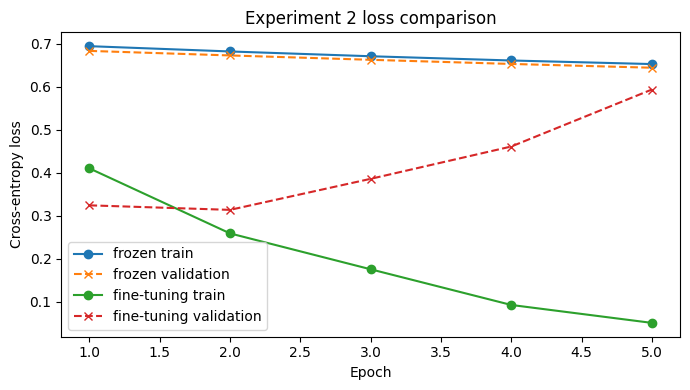

,experiment,accuracy,f1,trainable_parameters
1,Experiment 2 - frozen,0.7377,0.745907,1538
2,Experiment 2 - fine-tuning,0.8560,0.865697,66364418


In [6]:
frozen_model, frozen_training, frozen_metrics = train_and_test(
    new_pretrained(freeze_encoder=True),
    train_df,
    validation_df,
    test_df,
    MAX_LENGTH,
)
fine_tuned_model, fine_tuned_training, fine_tuned_metrics = train_and_test(
    new_pretrained(freeze_encoder=False),
    train_df,
    validation_df,
    test_df,
    MAX_LENGTH,
)
add_result("Experiment 2 - frozen", frozen_model, frozen_metrics, frozen_training, MAX_LENGTH, len(train_df))
add_result("Experiment 2 - fine-tuning", fine_tuned_model, fine_tuned_metrics, fine_tuned_training, MAX_LENGTH, len(train_df))
plot_loss(
    {"frozen": frozen_training["history"], "fine-tuning": fine_tuned_training["history"]},
    "Experiment 2 loss comparison",
    "loss_experiment_2.png",
)
pd.DataFrame(results).query("experiment.str.startswith('Experiment 2')", engine="python")[["experiment", "accuracy", "f1", "trainable_parameters"]]

# Experiment 3: Amount of training data

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:245: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:158: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/work

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:245: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:158: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/work

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:245: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:158: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/work

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:245: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:158: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/work

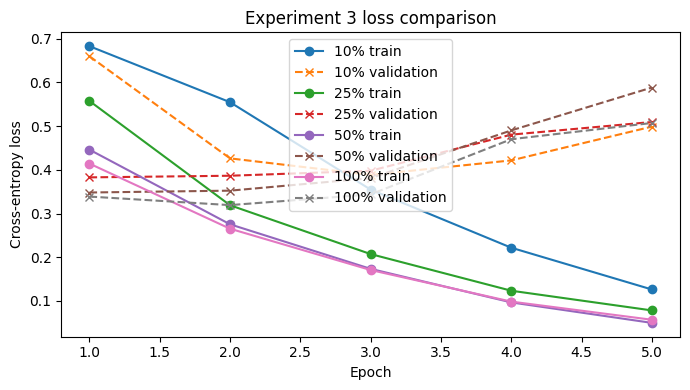

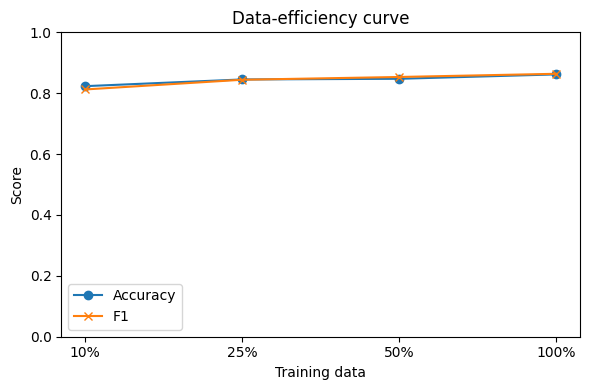

,training_data,accuracy,f1
0,10%,0.8231,0.812268
1,25%,0.8452,0.844203
2,50%,0.8474,0.853326
3,100%,0.8618,0.863816


In [7]:
data_histories = {}
data_rows = []
for fraction in (0.10, 0.25, 0.50, 1.00):
    subset = train_df.sample(frac=fraction, random_state=SEED).reset_index(drop=True)
    model, training, metrics = train_and_test(
        new_pretrained(freeze_encoder=False),
        subset,
        validation_df,
        test_df,
        MAX_LENGTH,
        evaluate_test=False,
    )
    label = f"{int(fraction * 100)}%"
    data_histories[label] = training["history"]
    add_result(f"Experiment 3 - {label} training data", model, metrics, training, MAX_LENGTH, len(subset))
    data_rows.append({"training_data": label, "accuracy": metrics["accuracy"], "f1": metrics["f1"]})
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

plot_loss(data_histories, "Experiment 3 loss comparison", "loss_experiment_3.png")
data_efficiency = pd.DataFrame(data_rows)
data_efficiency.to_csv(OUTPUT_DIR / "data_efficiency.csv", index=False)
plt.figure(figsize=(6, 4))
plt.plot(data_efficiency["training_data"], data_efficiency["accuracy"], marker="o", label="Accuracy")
plt.plot(data_efficiency["training_data"], data_efficiency["f1"], marker="x", label="F1")
plt.xlabel("Training data")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Data-efficiency curve")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "data_efficiency.png", dpi=150)
plt.show()
data_efficiency

# Experiment 4: Maximum sequence length

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:245: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:158: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/work

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:245: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:158: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/work

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:245: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device.type == "cuda")
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:158: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/work

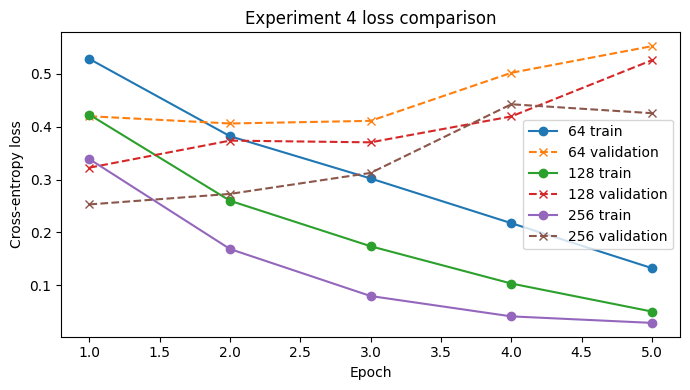

,experiment,max_length,accuracy,f1,training_time_seconds,gpu_memory_mb
7,Experiment 4 - max length 64,64,0.8120,0.812786,79.908212,2511.979004
8,Experiment 4 - max length 128,128,0.8640,0.869029,160.312301,2515.228516
9,Experiment 4 - max length 256,256,0.9015,0.902984,498.277679,2122.329590


In [8]:
length_histories = {}
for max_length in (64, 128, 256):
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    model, training, metrics = train_and_test(
        new_pretrained(freeze_encoder=False),
        train_df,
        validation_df,
        test_df,
        max_length,
        evaluate_test=False,
    )
    peak_memory_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if torch.cuda.is_available() else np.nan
    )
    add_result(
        f"Experiment 4 - max length {max_length}",
        model,
        metrics,
        training,
        max_length,
        len(train_df),
    )
    results[-1]["gpu_memory_mb"] = peak_memory_mb
    length_histories[str(max_length)] = training["history"]
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

plot_loss(length_histories, "Experiment 4 loss comparison", "loss_experiment_4.png")
pd.DataFrame(results).query("experiment.str.startswith('Experiment 4')", engine="python")[["experiment", "max_length", "accuracy", "f1", "training_time_seconds", "gpu_memory_mb"]]
     

# Experiment 5: Domain shift

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

test.parquet: reconstructing file:   0%|          |  0.00B / 92.2kB            

test.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

/kaggle/working/NLP/Lab8/src/pretrained_classification.py:196: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type == "cuda"):
/kaggle/working/NLP/Lab8/src/pretrained_classification.py:196: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=device.type == "cuda"):


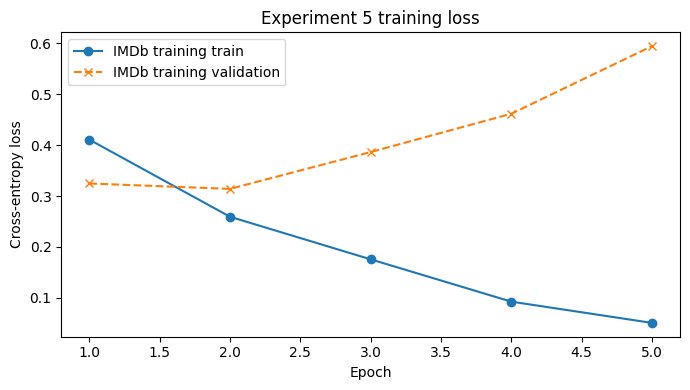

,experiment,accuracy,f1
10,Experiment 5 - in domain IMDb,0.856000,0.865697
11,Experiment 5 - out of domain Rotten Tomatoes,0.782364,0.800000


In [9]:
from datasets import load_dataset

rotten = load_dataset(
    "cornell-movie-review-data/rotten_tomatoes"
)
rotten_test = pd.DataFrame({
    "review": rotten["test"]["text"],
    "label": rotten["test"]["label"],
})
rotten_test["sentiment"] = rotten_test["label"].map({0: "negative", 1: "positive"})

rotten_loader = make_loader(rotten_test, MAX_LENGTH, shuffle=False)
imdb_domain_metrics = evaluate(fine_tuned_model, make_loader(test_df, MAX_LENGTH, False), device)
rotten_domain_metrics = evaluate(fine_tuned_model, rotten_loader, device)
results.extend([
    {
        "experiment": "Experiment 5 - in domain IMDb",
        "model": MODEL_NAME,
        "train_size": len(train_df),
        "max_length": MAX_LENGTH,
        "accuracy": imdb_domain_metrics["accuracy"],
        "precision": imdb_domain_metrics["precision"],
        "recall": imdb_domain_metrics["recall"],
        "f1": imdb_domain_metrics["f1"],
    },
    {
        "experiment": "Experiment 5 - out of domain Rotten Tomatoes",
        "model": MODEL_NAME,
        "train_size": len(train_df),
        "max_length": MAX_LENGTH,
        "accuracy": rotten_domain_metrics["accuracy"],
        "precision": rotten_domain_metrics["precision"],
        "recall": rotten_domain_metrics["recall"],
        "f1": rotten_domain_metrics["f1"],
    },
])
plot_loss({"IMDb training": fine_tuned_training["history"]}, "Experiment 5 training loss", "loss_experiment_5.png")
pd.DataFrame(results).query("experiment.str.startswith('Experiment 5')", engine="python")[["experiment", "accuracy", "f1"]]

# Application: IMDb sentiment classification

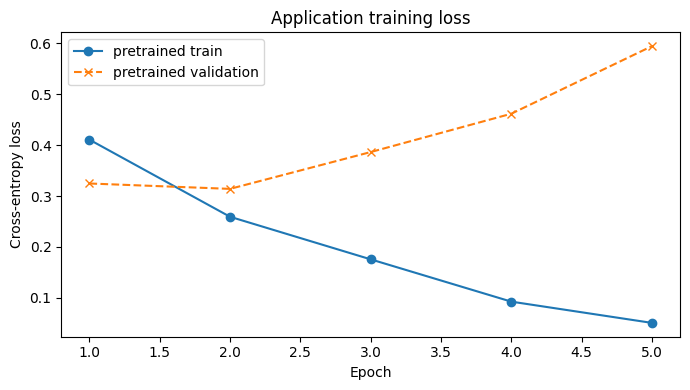

{'accuracy': 0.856, 'precision': 0.8110800419433765, 'recall': 0.9282, 'f1': 0.8656966983771684}


In [10]:
application_model = fine_tuned_model
application_training = fine_tuned_training
application_metrics = fine_tuned_metrics
add_result(
    "Application - pretrained fine-tuning",
    application_model,
    application_metrics,
    application_training,
    MAX_LENGTH,
    len(train_df),
)
plot_loss(
    {"pretrained": application_training["history"]},
    "Application training loss",
    "loss_application.png",
)
print({key: application_metrics[key] for key in ("accuracy", "precision", "recall", "f1")})


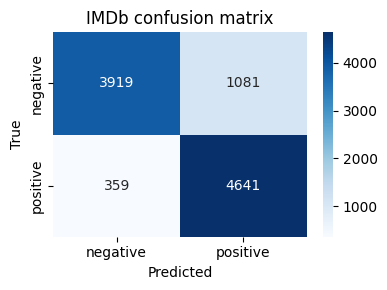

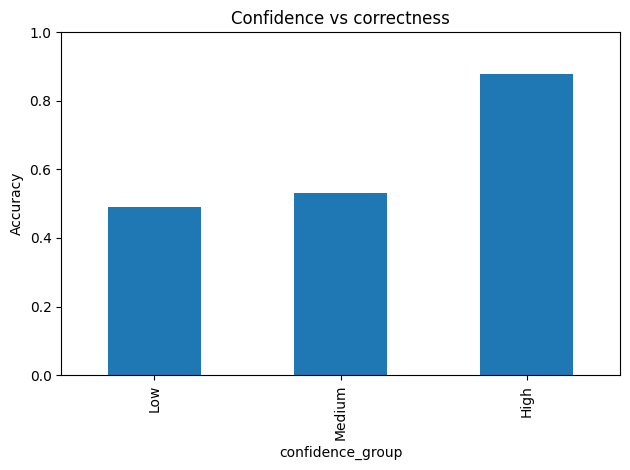

confidence_group
Low       0.489796
Medium    0.530892
High      0.878830
Name: correct, dtype: float64

In [11]:
cm = confusion_matrix(application_metrics["labels"], application_metrics["predictions"])
plt.figure(figsize=(4, 3))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["negative", "positive"],
    yticklabels=["negative", "positive"],
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("IMDb confusion matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

confidence_df = pd.DataFrame({
    "true": application_metrics["labels"],
    "prediction": application_metrics["predictions"],
    "confidence": application_metrics["probabilities"],
})
confidence_df["correct"] = confidence_df["true"] == confidence_df["prediction"]
confidence_df["confidence_group"] = pd.cut(
    confidence_df["confidence"],
    bins=[0.0, 0.6, 0.8, 1.0],
    labels=["Low", "Medium", "High"],
    include_lowest=True,
)
confidence_summary = confidence_df.groupby("confidence_group", observed=False)["correct"].mean()
confidence_summary.plot(
    kind="bar",
    ylim=(0, 1),
    ylabel="Accuracy",
    title="Confidence vs correctness",
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confidence_analysis.png", dpi=150)
plt.show()
confidence_summary

# Lưu kết quả

In [12]:
results_df = pd.DataFrame(results)
results_df.to_csv(OUTPUT_DIR / "results.csv", index=False)
results_df

,experiment,model,train_size,max_length,accuracy,precision,recall,f1,evaluation_split,training_time_seconds,parameters,trainable_parameters,gpu_memory_mb
0,Experiment 1 - from scratch,distilbert-base-uncased,10000,128,0.619100,0.605454,0.683800,0.642247,test,31.007458,4188418.0,4188418.0,NaN
1,Experiment 2 - frozen,distilbert-base-uncased,10000,128,0.737700,0.723276,0.770000,0.745907,test,98.761654,66364418.0,1538.0,NaN
2,Experiment 2 - fine-tuning,distilbert-base-uncased,10000,128,0.856000,0.811080,0.928200,0.865697,test,159.164511,66364418.0,66364418.0,NaN
3,Experiment 3 - 10% training data,distilbert-base-uncased,1000,128,0.823100,0.865250,0.765400,0.812268,validation,51.682065,66364418.0,66364418.0,NaN
4,Experiment 3 - 25% training data,distilbert-base-uncased,2500,128,0.845200,0.849676,0.838800,0.844203,validation,70.045198,66364418.0,66364418.0,NaN
5,Experiment 3 - 50% training data,distilbert-base-uncased,5000,128,0.847400,0.821429,0.887800,0.853326,validation,99.899333,66364418.0,66364418.0,NaN
6,Experiment 3 - 100% training data,distilbert-base-uncased,10000,128,0.861800,0.851399,0.876600,0.863816,validation,159.863967,66364418.0,66364418.0,NaN
7,Experiment 4 - max length 64,distilbert-base-uncased,10000,64,0.812000,0.809401,0.816200,0.812786,validation,79.908212,66364418.0,66364418.0,2511.979004
8,Experiment 4 - max length 128,distilbert-base-uncased,10000,128,0.864000,0.838039,0.902400,0.869029,validation,160.312301,66364418.0,66364418.0,2515.228516
9,Experiment 4 - max length 256,distilbert-base-uncased,10000,256,0.901500,0.889579,0.916800,0.902984,validation,498.277679,66364418.0,66364418.0,2122.329590
